In [5]:
import os
import os.path as op

import matplotlib.pyplot as plt
import pickle

import pandas as pd
from hnn_core.hnn_io import write_network_configuration, read_network_configuration
from hnn_core.dipole import average_dipoles
import sys

pth = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning'
sys.path.append(pth)
#
sys.path.append('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/utils')
from general_plot_utils import assign_color
import hnn_core
from hnn_core.params import _short_name

from hnn_core import duecker_ET_model, simulate_dipole, read_dipole, MPIBackend, jones_2009_model

from hnn_core.optimization import Optimizer
import numpy as np
hnn_core_root = op.join(op.dirname(hnn_core.__file__))
pathfig = op.join(pth, 'new_model_HNN/figures/csd_investigation')
os.makedirs(pathfig, exist_ok=True)

# The number of cores may need modifying depending on your current machine.
n_procs = 10
cols = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
plt.rcParams['pdf.fonttype'] = 'truetype'

# Set global font sizes
plt.rcParams['font.size'] = 12          # Default text size
plt.rcParams['axes.titlesize'] = 12      # Title size
plt.rcParams['axes.labelsize'] = 12      # Axis labels (xlabel, ylabel)
plt.rcParams['xtick.labelsize'] = 12    # X-axis tick labels
plt.rcParams['ytick.labelsize'] = 12     # Y-axis tick labels
plt.rcParams['legend.fontsize'] = 12     # Legend text

cm_neurons = np.array([[218,166,156], [164,30,79], [119,161,187],[92,114,183]])/255

In [6]:
exp_dpl = read_dipole(op.join(pth, 'hnn-data/MEG_detection_data/S1_SupraT.txt'))

In [7]:
prox1_weights_ampa = {'L2_basket': 0.02,
                        'L2_pyramidal': 0.1,
                        'L5_basket': 0.036,
                        'L5_pyramidal': 0.02}
prox1_weights_nmda = {'L2_basket': 0.0002,
                        'L2_pyramidal': 0.05,
                        'L5_basket': 0.004,
                        'L5_pyramidal': 0.002}

dist_weights_ampa = {'L2_basket': 0.00034,
                    'L2_pyramidal': 0.01,
                    'L5_pyramidal': 0.8}
dist_weights_nmda = {'L2_basket': 0.0003,
                    'L2_pyramidal': 0.001,
                    'L5_pyramidal': 0.9}

prox2_weights_ampa = {'L2_basket': 0.009,
                        'L2_pyramidal': 0.7,
                        'L5_basket': 0.0028,
                        'L5_pyramidal': 0.3}
prox2_weights_nmda = {'L2_basket': 0.007,
                    'L2_pyramidal': 0.1,
                    'L5_basket': 0.003,
                    'L5_pyramidal': 0.5}

In [8]:
tstop = exp_dpl.times[-1]
scale_factor = 1000
smooth_window_len = 5

In [10]:
net = duecker_ET_model()
net.set_cell_positions(inplane_distance=30.)
depths = list(range(-325, 2150, 100))
electrode_pos = [(135, 135, dep) for dep in depths]
net.add_electrode_array('shank1', electrode_pos)

synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                     'L5_basket': 1., 'L5_pyramidal': 1.}
net.add_evoked_drive('evprox1',
                        mu=16.,
                        sigma=2.5,
                        numspikes=2,
                        location='proximal',
                        weights_ampa=prox1_weights_ampa,
                        weights_nmda=prox1_weights_nmda,
                        synaptic_delays=synaptic_delays_p, event_seed=544)

# Distal
synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}

net.add_evoked_drive('evdist',
                        mu=56.5,
                        sigma=2.5,
                        numspikes=3,
                        location='distal',
                        weights_ampa=dist_weights_ampa,
                        weights_nmda=dist_weights_nmda,
                        synaptic_delays=synaptic_delays_d, event_seed=544)

net.add_evoked_drive('evprox2',
                    mu=95,
                    sigma=10,
                    numspikes=3,
                    location='proximal',
                    weights_ampa=prox2_weights_ampa,
                    weights_nmda=prox2_weights_nmda,
                    synaptic_delays=synaptic_delays_p, event_seed=544)

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net, tstop=tstop, n_trials=1,bsl_cor='calcium')[0]

dpl.scale(scale_factor).smooth(smooth_window_len)

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading cu

In [11]:
zl5pyr = net.pos_dict['L5_pyramidal'][0][-1]
zl2pyr = net.pos_dict['L2_pyramidal'][0][-1]

bsll5pyr = zl5pyr - (net.cell_types['L5_pyramidal']['cell_object'].sections['basal_1'].L + net.cell_types['L5_pyramidal']['cell_object'].sections['basal_2'].L/2)
bsll2pyr = zl2pyr - (net.cell_types['L2_pyramidal']['cell_object'].sections['basal_1'].L + net.cell_types['L2_pyramidal']['cell_object'].sections['basal_2'].L/2)

tuftl5 = zl5pyr
sections = ['soma', 'apical_trunk', 'apical_1', 'apical_2']
for section in sections:
    tuftl5 += net.cell_types['L5_pyramidal']['cell_object'].sections[section].L
tuftl5 += net.cell_types['L2_pyramidal']['cell_object'].sections['apical_tuft'].L/2

oblqul5 = zl5pyr + net.cell_types['L5_pyramidal']['cell_object'].sections['apical_trunk'].L + net.cell_types['L5_pyramidal']['cell_object'].sections['apical_oblique'].diam

In [12]:
net.cell_types['L5_pyramidal']['cell_object'].sections['apical_oblique'].diam

5.1

In [13]:
net.cell_types['L5_pyramidal']['cell_object'].cell_tree

{('apical_trunk', 0): [('apical_trunk', 1)],
 ('apical_1', 0): [('apical_1', 1)],
 ('apical_2', 0): [('apical_2', 1)],
 ('apical_tuft', 0): [('apical_tuft', 1)],
 ('apical_oblique', 0): [('apical_oblique', 1)],
 ('basal_1', 0): [('basal_1', 1)],
 ('basal_2', 0): [('basal_2', 1)],
 ('basal_3', 0): [('basal_3', 1)],
 ('soma', 0): [('soma', 1), ('basal_1', 0)],
 ('soma', 1): [('apical_trunk', 0)],
 ('apical_trunk', 1): [('apical_1', 0), ('apical_oblique', 0)],
 ('apical_1', 1): [('apical_2', 0)],
 ('apical_2', 1): [('apical_tuft', 0)],
 ('basal_1', 1): [('basal_2', 0), ('basal_3', 0)]}

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/viz.py:1867: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


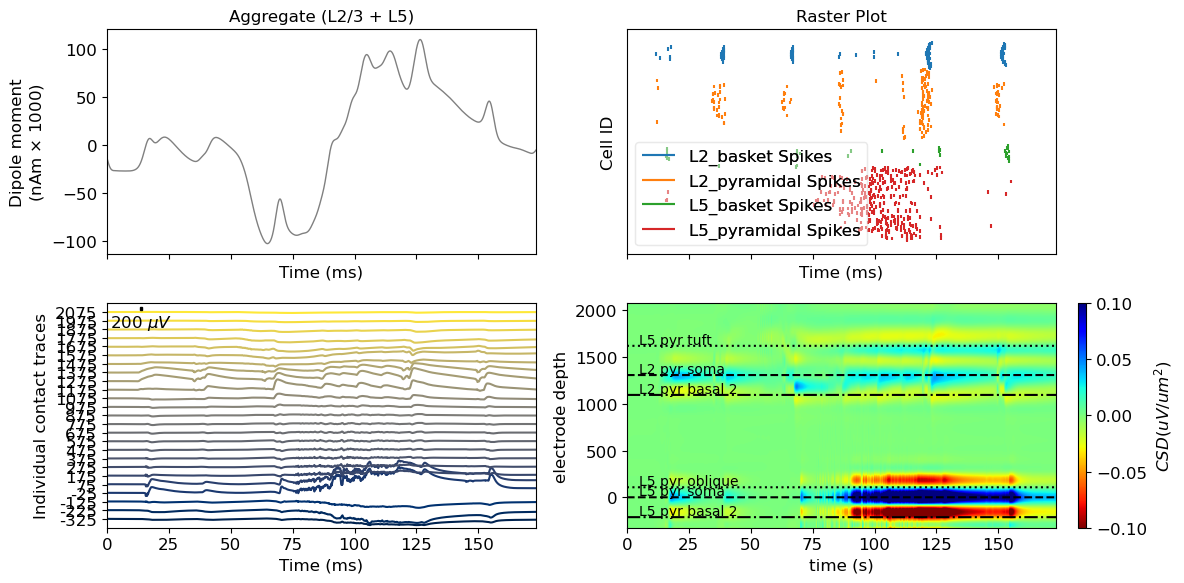

In [14]:
fig, ax = plt.subplots(2,2,figsize=(12,6), sharex=True, constrained_layout=True)
dpl.plot(ax=ax[0,0], show=False)
net.cell_response.plot_spikes_raster(ax=ax[0,1], show=False)
net.rec_arrays['shank1'][0].plot_lfp(ax=ax[1,0], show=False, voltage_offset=500)
net.rec_arrays['shank1'][0].plot_csd(ax=ax[1,1], show=False, sink='r', vmin=-0.1, vmax=0.1)

ax[1,1].plot(dpl.times, np.ones_like(dpl.times)*zl5pyr, 'k--')
ax[1,1].text(5, zl5pyr+20, 'L5 pyr soma', fontsize=10)
ax[1,1].plot(dpl.times, np.ones_like(dpl.times)*bsll5pyr, 'k-.')
ax[1,1].text(5, bsll5pyr+20, 'L5 pyr basal 2', fontsize=10)
ax[1,1].plot(dpl.times, np.ones_like(dpl.times)*tuftl5, 'k:')
ax[1,1].text(5, tuftl5+20, 'L5 pyr tuft', fontsize=10)
ax[1,1].plot(dpl.times, np.ones_like(dpl.times)*oblqul5, 'k:')
ax[1,1].text(5, oblqul5+20, 'L5 pyr oblique', fontsize=10)
ax[1,1].plot(dpl.times, np.ones_like(dpl.times)*zl2pyr, 'k--')
ax[1,1].text(5, zl2pyr+20, 'L2 pyr soma', fontsize=10)
ax[1,1].plot(dpl.times, np.ones_like(dpl.times)*bsll2pyr, 'k-.')
ax[1,1].text(5, bsll2pyr+20, 'L2 pyr basal 2', fontsize=10)

fig.savefig(os.path.join(pathfig, 'csd_full_model.png'), dpi=300)


/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/dipole.py:83: UserWarning: No connections instantiated in network. Consider using net = jones_2009_model() or net = law_2021_model() to create a predefined network from published models.
  )
/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/dipole.py:91: UserWarning: No external drives or biases loaded
  if drive["dynamics"]["tstop"] is None:


MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading cu

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/viz.py:1867: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


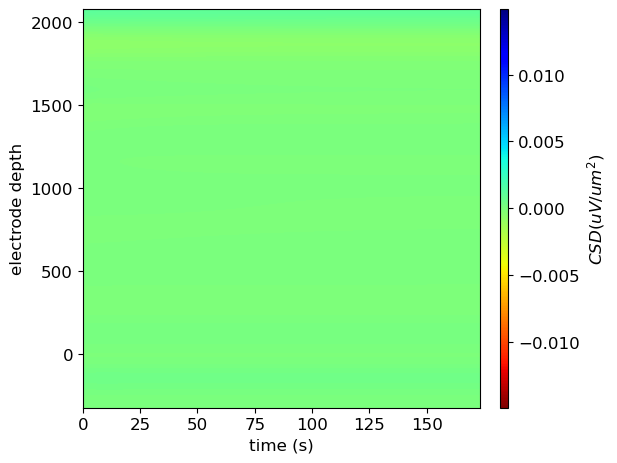

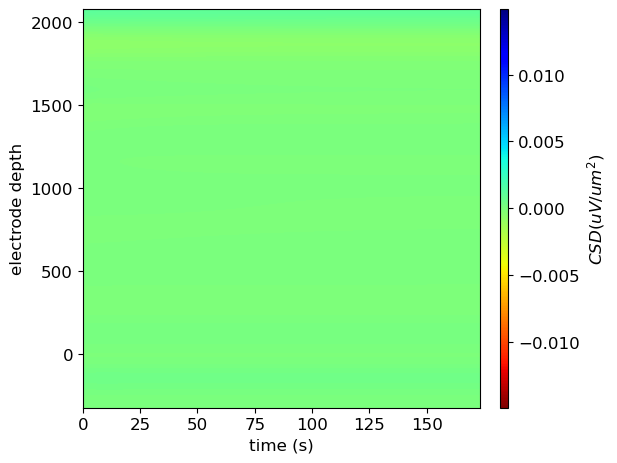

In [17]:
net = duecker_ET_model()
net.clear_connectivity()
net.set_cell_positions(inplane_distance=30.)
depths = list(range(-325, 2150, 100))
electrode_pos = [(135, 135, dep) for dep in depths]
net.add_electrode_array('shank1', electrode_pos)


with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net, tstop=tstop, n_trials=1,bsl_cor='calcium')[0]

net.rec_arrays['shank1'][0].plot_csd(show=False, sink='r')


MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading cu

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/viz.py:1867: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


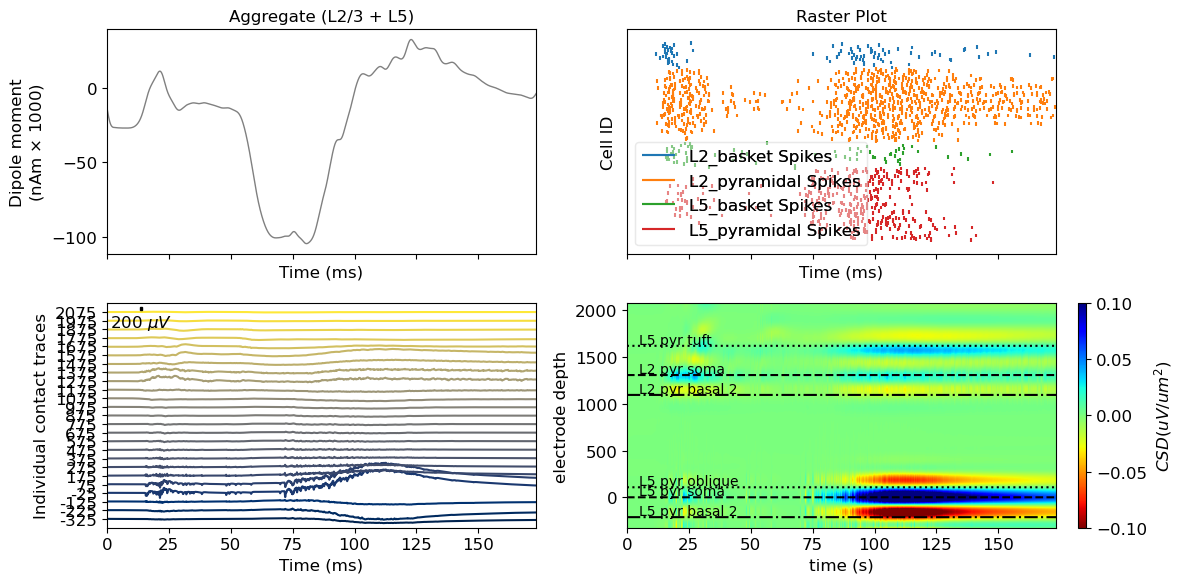

In [15]:
net = duecker_ET_model()
net.clear_connectivity()
net.set_cell_positions(inplane_distance=30.)
depths = list(range(-325, 2150, 100))
electrode_pos = [(135, 135, dep) for dep in depths]
net.add_electrode_array('shank1', electrode_pos)

synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                     'L5_basket': 1., 'L5_pyramidal': 1.}
net.add_evoked_drive('evprox1',
                        mu=16.,
                        sigma=2.5,
                        numspikes=2,
                        location='proximal',
                        weights_ampa=prox1_weights_ampa,
                        weights_nmda=prox1_weights_nmda,
                        synaptic_delays=synaptic_delays_p, event_seed=544)

# Distal
synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}

net.add_evoked_drive('evdist',
                        mu=56.5,
                        sigma=2.5,
                        numspikes=3,
                        location='distal',
                        weights_ampa=dist_weights_ampa,
                        weights_nmda=dist_weights_nmda,
                        synaptic_delays=synaptic_delays_d, event_seed=544)

net.add_evoked_drive('evprox2',
                    mu=95,
                    sigma=10,
                    numspikes=3,
                    location='proximal',
                    weights_ampa=prox2_weights_ampa,
                    weights_nmda=prox2_weights_nmda,
                    synaptic_delays=synaptic_delays_p, event_seed=544)

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net, tstop=tstop, n_trials=1,bsl_cor='calcium')[0]

dpl.scale(scale_factor).smooth(smooth_window_len)
fig, ax = plt.subplots(2,2,figsize=(12,6), sharex=True, constrained_layout=True)
dpl.plot(ax=ax[0,0], show=False)
net.cell_response.plot_spikes_raster(ax=ax[0,1], show=False)
net.rec_arrays['shank1'][0].plot_lfp(ax=ax[1,0], show=False, voltage_offset=500)
net.rec_arrays['shank1'][0].plot_csd(ax=ax[1,1], show=False, sink='r', vmin=-0.1, vmax=0.1)

ax[1,1].plot(dpl.times, np.ones_like(dpl.times)*zl5pyr, 'k--')
ax[1,1].text(5, zl5pyr+20, 'L5 pyr soma', fontsize=10)
ax[1,1].plot(dpl.times, np.ones_like(dpl.times)*bsll5pyr, 'k-.')
ax[1,1].text(5, bsll5pyr+20, 'L5 pyr basal 2', fontsize=10)
ax[1,1].plot(dpl.times, np.ones_like(dpl.times)*tuftl5, 'k:')
ax[1,1].text(5, tuftl5+20, 'L5 pyr tuft', fontsize=10)
ax[1,1].plot(dpl.times, np.ones_like(dpl.times)*oblqul5, 'k:')
ax[1,1].text(5, oblqul5+20, 'L5 pyr oblique', fontsize=10)
ax[1,1].plot(dpl.times, np.ones_like(dpl.times)*zl2pyr, 'k--')
ax[1,1].text(5, zl2pyr+20, 'L2 pyr soma', fontsize=10)
ax[1,1].plot(dpl.times, np.ones_like(dpl.times)*bsll2pyr, 'k-.')
ax[1,1].text(5, bsll2pyr+20, 'L2 pyr basal 2', fontsize=10)

fig.savefig(os.path.join(pathfig, 'csd_clear_conn.png'), dpi=300)

In [11]:
net.cell_types['L5_pyramidal']['cell_object'].sections['apical_1'].mechs

{'NaTa_t': {'gbar_NaTa_t': 0.01065},
 'SKv3_1': {'gbar_SKv3_1': 0.000261},
 'Ca_HVA': {'gbar_Ca_HVA': [[np.float64(0.038461538461538464),
    np.float64(0.11538461538461539),
    np.float64(0.19230769230769232),
    np.float64(0.2692307692307693),
    np.float64(0.34615384615384615),
    np.float64(0.42307692307692313),
    np.float64(0.5),
    np.float64(0.576923076923077),
    np.float64(0.6538461538461539),
    np.float64(0.7307692307692308),
    np.float64(0.8076923076923077),
    np.float64(0.8846153846153847),
    np.float64(0.9615384615384616)],
   [np.float64(3.093854871794872e-05),
    np.float64(3.627044615384616e-05),
    np.float64(4.160234358974359e-05),
    np.float64(4.693424102564103e-05),
    np.float64(5.2266138461538456e-05),
    np.float64(5.7598035897435896e-05),
    np.float64(6.292993333333333e-05),
    np.float64(6.826183076923078e-05),
    np.float64(7.359372820512821e-05),
    np.float64(7.892562564102565e-05),
    np.float64(8.425752307692309e-05),
    np.flo

In [66]:
def block_conductances(net):

    for cell in ['L2_pyramidal', 'L5_pyramidal']:
        cell_obj = net.cell_types[cell]['cell_object']
        for sec_name, sec in cell_obj.sections.items():
            for mech in sec.mechs.keys():
                if mech != 'pas':
                    for gbar in sec.mechs[mech]:
                        if type(sec.mechs[mech][gbar])==float or type(sec.mechs[mech][gbar])==int:
                            sec.mechs[mech][gbar] = 0.0
                        else:
                            for i in range(len(sec.mechs[mech][gbar][0])):
                                sec.mechs[mech][gbar][i] = 0.0
    return net

In [69]:
net = duecker_2025_ET_model()
net = block_conductances(net)
net.clear_connectivity()

IndexError: list assignment index out of range

In [70]:
net.cell_types['L5_pyramidal']['cell_object'].sections['apical_1'].mechs

{'NaTa_t': {'gbar_NaTa_t': 0.01065},
 'SKv3_1': {'gbar_SKv3_1': 0.000261},
 'Ca_HVA': {'gbar_Ca_HVA': [[np.float64(0.038461538461538464),
    np.float64(0.11538461538461539),
    np.float64(0.19230769230769232),
    np.float64(0.2692307692307693),
    np.float64(0.34615384615384615),
    np.float64(0.42307692307692313),
    np.float64(0.5),
    np.float64(0.576923076923077),
    np.float64(0.6538461538461539),
    np.float64(0.7307692307692308),
    np.float64(0.8076923076923077),
    np.float64(0.8846153846153847),
    np.float64(0.9615384615384616)],
   [np.float64(3.093854871794872e-05),
    np.float64(3.627044615384616e-05),
    np.float64(4.160234358974359e-05),
    np.float64(4.693424102564103e-05),
    np.float64(5.2266138461538456e-05),
    np.float64(5.7598035897435896e-05),
    np.float64(6.292993333333333e-05),
    np.float64(6.826183076923078e-05),
    np.float64(7.359372820512821e-05),
    np.float64(7.892562564102565e-05),
    np.float64(8.425752307692309e-05),
    np.flo

In [71]:
net.set_cell_positions(inplane_distance=30.)
depths = list(range(-325, 2150, 100))
electrode_pos = [(135, 135, dep) for dep in depths]
net.add_electrode_array('shank1', electrode_pos)

synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                     'L5_basket': 1., 'L5_pyramidal': 1.}
net.add_evoked_drive('evprox1',
                        mu=16.,
                        sigma=2.5,
                        numspikes=2,
                        location='proximal',
                        weights_ampa=prox1_weights_ampa,
                        weights_nmda=prox1_weights_nmda,
                        synaptic_delays=synaptic_delays_p, event_seed=544)

# Distal
synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}

net.add_evoked_drive('evdist',
                        mu=56.5,
                        sigma=2.5,
                        numspikes=3,
                        location='distal',
                        weights_ampa=dist_weights_ampa,
                        weights_nmda=dist_weights_nmda,
                        synaptic_delays=synaptic_delays_d, event_seed=544)

net.add_evoked_drive('evprox2',
                    mu=95,
                    sigma=10,
                    numspikes=3,
                    location='proximal',
                    weights_ampa=prox2_weights_ampa,
                    weights_nmda=prox2_weights_nmda,
                    synaptic_delays=synaptic_delays_p, event_seed=544)

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net, tstop=tstop, n_trials=1,bsl_cor='calcium')[0]

dpl.scale(scale_factor).smooth(smooth_window_len)
fig, ax = plt.subplots(2,2,figsize=(12,6), sharex=True, constrained_layout=True)
dpl.plot(ax=ax[0,0], show=False)
net.cell_response.plot_spikes_raster(ax=ax[0,1], show=False)
net.rec_arrays['shank1'][0].plot_lfp(ax=ax[1,0], show=False, voltage_offset=500)
net.rec_arrays['shank1'][0].plot_csd(ax=ax[1,1], show=False, sink='r', vmin=-0.1, vmax=0.1)

ax[1,1].plot(dpl.times, np.ones_like(dpl.times)*zl5pyr, 'k--')
ax[1,1].text(5, zl5pyr+20, 'L5 pyr soma', fontsize=10)
ax[1,1].plot(dpl.times, np.ones_like(dpl.times)*bsll5pyr, 'k-.')
ax[1,1].text(5, bsll5pyr+20, 'L5 pyr basal 2', fontsize=10)
ax[1,1].plot(dpl.times, np.ones_like(dpl.times)*tuftl5, 'k:')
ax[1,1].text(5, tuftl5+20, 'L5 pyr tuft', fontsize=10)
ax[1,1].plot(dpl.times, np.ones_like(dpl.times)*oblqul5, 'k:')
ax[1,1].text(5, oblqul5+20, 'L5 pyr oblique', fontsize=10)
ax[1,1].plot(dpl.times, np.ones_like(dpl.times)*zl2pyr, 'k--')
ax[1,1].text(5, zl2pyr+20, 'L2 pyr soma', fontsize=10)
ax[1,1].plot(dpl.times, np.ones_like(dpl.times)*bsll2pyr, 'k-.')
ax[1,1].text(5, bsll2pyr+20, 'L2 pyr basal 2', fontsize=10)

fig.savefig(os.path.join(pathfig, 'csd_blocked_cond.png'), dpi=300)

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Load

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/parallel_backends.py:175: UserWarning: Child process failed unexpectedly
  warn("Child process failed unexpectedly")


RuntimeError: MPI simulation failed. Return code: 2